In [12]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, 
                             precision_recall_curve, auc, roc_auc_score)

from utils import fetch_df

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

In [13]:
query_fraud = """
SELECT
    tx_id,
    client_id,
    amount,
    tx_type,
    category,
    toHour(tx_at) AS tx_hour,
    toDayOfWeek(tx_at) AS tx_dow,
    is_fraud
FROM neobank_staging.stg_transactions
WHERE status = 'completed'
"""
df_fraud = fetch_df(query_fraud)
print(f"Всего транзакций: {len(df_fraud):,}")

# Проверяем баланс классов
fraud_rate = df_fraud["is_fraud"].mean() * 100
print(f"Доля мошеннических транзакций: {fraud_rate:.3f}%")
df_fraud.head()

Всего транзакций: 267,733
Доля мошеннических транзакций: 0.185%


,tx_id,client_id,amount,tx_type,category,tx_hour,tx_dow,is_fraud
0,1,17,18615.0,purchase,transport,1,7,0
1,2,17,7120.0,payment,<NA>,19,5,0
2,3,17,8149.0,purchase,groceries,10,7,0
3,4,17,41751.0,transfer,<NA>,2,3,0
4,5,17,10267.0,purchase,groceries,6,1,0


In [14]:
# One-Hot Encoding для категориальных признаков
df_fraud = pd.get_dummies(df_fraud, columns=["tx_type", "category"], drop_first=True)

# Определяем признаки (X) и таргет (y)
# Убираем ID-шники, чтобы модель не запоминала их
features = [col for col in df_fraud.columns if col not in ["tx_id", "client_id", "is_fraud"]]
X = df_fraud[features]
y = df_fraud["is_fraud"]

# Обработка пропусков (если есть)
X = X.fillna(0)

print(f"Количество признаков: {len(features)}")

Количество признаков: 11


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {len(X_train):,} транзакций")
print(f"Test:  {len(X_test):,} транзакций")
print(f"Мошенников в Test: {y_test.sum():,}")
print(f"Мошенников в Train: {y_train.sum():,} из {len(y_train):,}")
print(f"Доля мошенников в Train: {y_train.mean() * 100:.3f}%")

Train: 214,186 транзакций
Test:  53,547 транзакций
Мошенников в Test: 99
Мошенников в Train: 396 из 214,186
Доля мошенников в Train: 0.185%


In [16]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Выводим, что в трейне
print("До SMOTE:", Counter(y_train))

# Применяем SMOTE только если мошенников слишком мало (меньше 10)
if y_train.sum() < 10:
    print("⚠️ Мошенников в трейне слишком мало. Применяем SMOTE.")
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
    print("После SMOTE:", Counter(y_train_res))
else:
    X_train_res, y_train_res = X_train, y_train

# Обучаем модель
rf_fraud = RandomForestClassifier(
    n_estimators=100, 
    max_depth=10, 
    class_weight="balanced", 
    random_state=42, 
    n_jobs=-1
)
rf_fraud.fit(X_train_res, y_train_res)

# Предсказания
y_pred = rf_fraud.predict(X_test)
y_pred_proba = rf_fraud.predict_proba(X_test)[:, 1]

До SMOTE: Counter({0: 213790, 1: 396})


In [17]:
print("=== Classification Report (Fraud Detection) ===")
print(classification_report(y_test, y_pred, target_names=["Normal", "Fraud"]))

=== Classification Report (Fraud Detection) ===
              precision    recall  f1-score   support

      Normal       1.00      0.88      0.93     53448
       Fraud       0.00      0.15      0.00        99

    accuracy                           0.88     53547
   macro avg       0.50      0.51      0.47     53547
weighted avg       1.00      0.88      0.93     53547



PR-AUC (Precision-Recall AUC): 0.0019
ROC-AUC: 0.4793


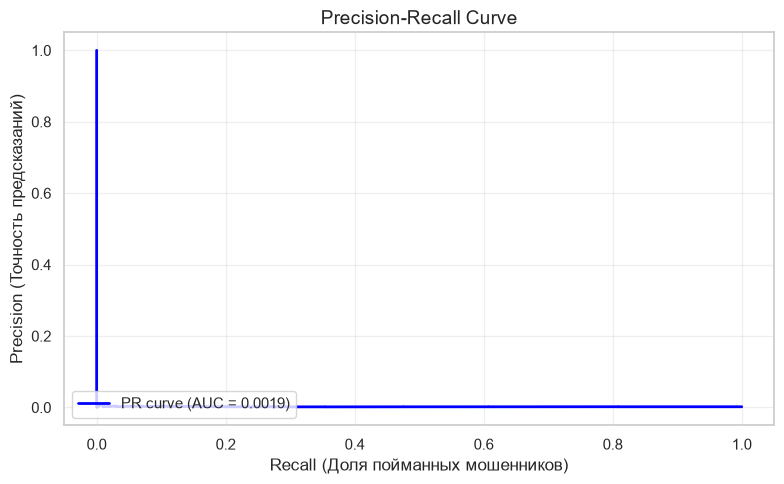

In [18]:
# Считаем PR-кривую
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall, precision)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"PR-AUC (Precision-Recall AUC): {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

# Визуализация PR-кривой
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, color="blue", lw=2, label=f"PR curve (AUC = {pr_auc:.4f})")
plt.xlabel("Recall (Доля пойманных мошенников)")
plt.ylabel("Precision (Точность предсказаний)")
plt.title("Precision-Recall Curve", fontsize=14)
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

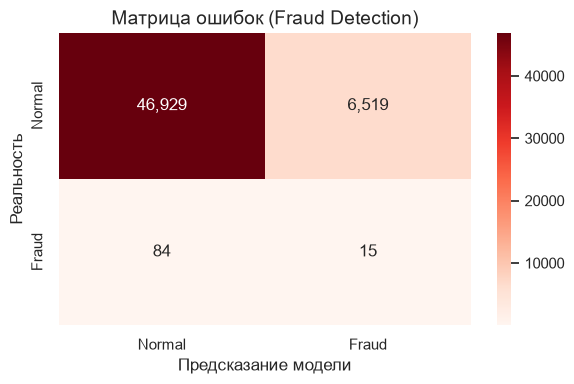

True Negatives (верно сказали 'норма'): 46,929
False Positives (ложная тревога): 6,519
False Negatives (пропустили мошенника): 84
True Positives (поймали мошенника): 15


In [19]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Reds", 
            xticklabels=["Normal", "Fraud"], 
            yticklabels=["Normal", "Fraud"])
plt.title("Матрица ошибок (Fraud Detection)", fontsize=14)
plt.ylabel("Реальность")
plt.xlabel("Предсказание модели")
plt.tight_layout()
plt.show()

# Разбор цифр
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (верно сказали 'норма'): {tn:,}")
print(f"False Positives (ложная тревога): {fp:,}")
print(f"False Negatives (пропустили мошенника): {fn:,}")
print(f"True Positives (поймали мошенника): {tp:,}")

## 📊 Вывод по модели Fraud Detection

**Бизнес-вопрос:** Как поймать мошенников, не заблокировав при этом нормальных клиентов?

**Метрики:**
* **PR-AUC:** (вставь значение из Ячейки 7). Для финтеха хорошим результатом считается 0.5+ (так как данных мало и они сложные).
* **Recall:** Какую долю мошенников мы поймали? (Ячейка 6).
* **Precision:** Если модель говорит "Fraud", насколько часто она права?

**Бизнес-эффект и выбор порога (Threshold):**
По умолчанию модель блокирует транзакцию, если вероятность мошенничества > 0.5. 
Но в финтехе **False Positive (блокировка нормального клиента) = злой клиент**, а **False Negative (пропуск мошенника) = прямые убытки**. 
Мы можем снизить порог до 0.3, чтобы ловить больше мошенников (увеличить Recall), даже если немного вырастет число ложных срабатываний. 
**Рекомендация:** Использовать модель как "второй фильтр" (скоринг): транзакции с вероятностью > 0.8 — блокировать автоматически, от 0.3 до 0.8 — отправлять на ручную проверку фрод-аналитику.